In [11]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [15]:
import pandas as pd
import os

path_train = "/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/train (1).csv"
path_val = "/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/validation (1).csv"
path_test = "/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/test (1) (1).csv"

# Si les données sont déjà chargées en mémoire, on évite de bloquer sur une erreur de lecture
try:
    if 'train_df' in globals() and isinstance(train_df, pd.DataFrame) and len(train_df) > 0:
        print("Les DataFrames sont déjà présents en mémoire et prêts à l'usage.")
    else:
        raise NameError()
except (NameError, KeyError):
    # Rafraîchissement forcé du cache Google Drive en listant le répertoire
    try:
        os.listdir("/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset")
    except Exception:
        pass

    train_df = pd.read_csv(path_train)
    val_df = pd.read_csv(path_val)
    test_df = pd.read_csv(path_test)
    print("Données chargées depuis le Drive avec succès.")

Données chargées depuis le Drive avec succès.


In [16]:
import os

path_projet = "/content/drive/MyDrive/projet covid radiographie pulmonaire"
try:
    contenu = os.listdir(path_projet)
    print(f"Contenu du dossier '{path_projet}' :")
    for element in sorted(contenu):
        print(f" - {element}")
except Exception as e:
    print(f"Erreur lors de l'accès au dossier : {e}")

Contenu du dossier '/content/drive/MyDrive/projet covid radiographie pulmonaire' :
 - COVID-19_Radiography_Dataset
 - best_cnn_no_aug_no_oversampling.keras
 - best_cnn_with_aug_and_oversampling.keras
 - best_cnn_with_aug_no_oversampling.keras
 - best_cnn_with_oversampling.keras
 - colab_temp_test_preprocessing
 - colab_temp_test_preprocessing_processed
 - dataset_summary.csv


In [17]:
import os

# 1. Vérifier dans le sous-dossier du dataset
sub_path = "/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset"
if os.path.exists(sub_path):
    print(f"Contenu de '{sub_path}' :")
    for element in sorted(os.listdir(sub_path)):
        print(f" - {element}")
else:
    print(f"Le sous-dossier '{sub_path}' n'existe pas.")

print("\n" + "="*50 + "\n")

# 2. Chercher globalement tous les fichiers .csv dans le dossier du projet pour les localiser rapidement
print("Recherche de tous les fichiers .csv présents dans le dossier du projet :")
found_csvs = []
for root, dirs, files in os.walk("/content/drive/MyDrive/projet covid radiographie pulmonaire"):
    for file in files:
        if file.endswith('.csv'):
            found_csvs.append(os.path.join(root, file))

if found_csvs:
    for csv_path in found_csvs:
        print(f" - Trouvé : {csv_path}")
else:
    print("Aucun fichier CSV n'a été trouvé dans l'arborescence du projet.")

Contenu de '/content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset' :
 - COVID
 - COVID.metadata.xlsx
 - Lung_Opacity
 - Lung_Opacity.metadata.xlsx
 - Normal
 - Normal.metadata.xlsx
 - README.md.txt
 - Viral Pneumonia
 - Viral Pneumonia.metadata.xlsx
 - test (1) (1).csv
 - train (1).csv
 - validation (1).csv


Recherche de tous les fichiers .csv présents dans le dossier du projet :
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/dataset_summary.csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/test (1) (1).csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/train (1).csv
 - Trouvé : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset/validation (1).csv


In [18]:
# CONFLIT — MODIFICATION : un seul dossier Drive imposé pour les CSV et images.
# Monter Google Drive dans Colab AVANT cette cellule :
# from google.colab import drive
# drive.mount("/content/drive")
# Modifier uniquement PROJECT_DIR selon le dossier partagé.
from pathlib import Path
import pandas as pd
import os
import tensorflow as tf

PROJECT_DIR = Path("/content/drive/MyDrive/projet covid radiographie pulmonaire")
DATA_DIR = PROJECT_DIR
DATASET_ROOT = PROJECT_DIR / "COVID-19_Radiography_Dataset"

# Rafraîchissement forcé du cache Google Drive pour limiter les erreurs d'accès réseau
try:
    os.listdir(str(PROJECT_DIR))
except Exception:
    pass

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dossier projet introuvable : {DATA_DIR}. Monter Drive et vérifier PROJECT_DIR.")
if not DATASET_ROOT.is_dir():
    # Fallback si le dossier d'images se nomme 'imagerie' à la racine
    if (PROJECT_DIR / "imagerie").is_dir():
        DATASET_ROOT = PROJECT_DIR / "imagerie"
    else:
        raise FileNotFoundError(f"Dossier images introuvable : {DATASET_ROOT}. Respecter l'arborescence Kaggle.")

OUTPUT_DIR = Path(".")  # CONFLIT — MODIFICATION : sorties locales, sans chemin Drive fragile.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Utilisation des DataFrames en mémoire s'ils existent déjà pour contourner les blocages d'accès du Drive
if 'train_df' in globals() and isinstance(train_df, pd.DataFrame) and len(train_df) > 0:
    print("Réutilisation des DataFrames déjà présents en mémoire active.")
else:
    train_df = pd.read_csv(DATA_DIR / "train.csv")
    val_df = pd.read_csv(DATA_DIR / "validation.csv")
    test_df = pd.read_csv(DATA_DIR / "test.csv")

# CONFLIT — AJOUT : ces effectifs sont ceux du split de référence E0/E4.
EXPECTED = {"train": 13545, "validation": 3387, "test": 4233}
for name, frame in (("train", train_df), ("validation", val_df), ("test", test_df)):
    assert {"filepath", "target"}.issubset(frame.columns), f"{name}: colonnes filepath/target manquantes"
    assert len(frame) == EXPECTED[name], f"CONFLIT split {name}: {len(frame)} au lieu de {EXPECTED[name]}"
    assert frame["filepath"].notna().all() and frame["target"].notna().all(), f"{name}: valeurs manquantes"
    assert set(frame["target"].astype(str).unique()) <= {"0", "1"}, f"{name}: target non binaire"
    assert frame["filepath"].is_unique, f"{name}: chemins dupliqués"
    print(f"{name}: {len(frame)} images; COVID={sum(frame['target'].astype(str)=='1')}")
train_paths, val_paths, test_paths = (set(d["filepath"].astype(str)) for d in (train_df, val_df, test_df))
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "CONFLIT : images présentes dans plusieurs splits"

# CONFLIT — MODIFICATION : affectations explicites, séparées et cohérentes avec E0.
train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
test_gen_df = test_df.copy()

# CONFLIT — AJOUT : conversion des étiquettes pour les générateurs binaires.
train_gen_df["target_str"] = train_gen_df["target"].astype(str)
val_gen_df["target_str"] = val_gen_df["target"].astype(str)
test_gen_df["target_str"] = test_gen_df["target"].astype(str)

# CONFLIT — MODIFICATION : reconstituer les chemins depuis le dossier dataset,
# sans toucher aux CSV ni modifier les appartenances train/validation/test.
def resolve_image_path(csv_path):
    normalized = str(csv_path).replace("\\", "/")
    marker = "COVID-19_Radiography_Dataset/"
    if marker not in normalized:
        filename = Path(normalized).name
        for subdir in ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]:
            possible_file = DATASET_ROOT / subdir / "images" / filename
            if possible_file.is_file():
                return str(possible_file)
        raise ValueError(f"CONFLIT : impossible de résoudre l'image : {csv_path}")
    relative = normalized.split(marker, 1)[1]
    parts = Path(relative).parts
    if len(parts) != 3 or parts[1] != "images" or parts[0] not in {
        "COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"
    }:
        raise ValueError(f"CONFLIT : structure d'image inattendue : {csv_path}")
    return str(DATASET_ROOT.joinpath(*parts))

train_gen_df["filepath"] = train_gen_df["filepath"].map(resolve_image_path)
val_gen_df["filepath"] = val_gen_df["filepath"].map(resolve_image_path)
test_gen_df["filepath"] = test_gen_df["filepath"].map(resolve_image_path)

# CONFLIT — AJOUT : vérifier les trois ensembles, y compris le test non utilisé à l'entraînement.
print("DATASET_ROOT :", DATASET_ROOT)
for name, frame in (("train", train_gen_df), ("validation", val_gen_df), ("test", test_gen_df)):
    missing = [p for p in frame["filepath"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(
            f"CONFLIT {name}: {len(missing)} images introuvables ; exemple : {missing[0]}. "
            "Vérifier PROJECT_DIR et la structure Kaggle avant de lancer fit()."
        )
    print(f"{name} : {len(frame)} chemins vérifiés")

BATCH_SIZE = 32
IMG_HEIGHT, IMG_WIDTH = 224, 224
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

Réutilisation des DataFrames déjà présents en mémoire active.
train: 13545 images; COVID=2314
validation: 3387 images; COVID=579
test: 4233 images; COVID=723
DATASET_ROOT : /content/drive/MyDrive/projet covid radiographie pulmonaire/COVID-19_Radiography_Dataset
train : 13545 chemins vérifiés
validation : 3387 chemins vérifiés
test : 4233 chemins vérifiés


In [19]:
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=10,
    width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=False
)
val_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_gen_df, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=True, seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_gen_df, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=False
)
assert train_generator.n == len(train_gen_df), "CONFLIT : images train écartées par Keras"
assert val_generator.n == 3387, "CONFLIT : validation différente du split commun"
assert train_generator.class_indices == val_generator.class_indices == {"0": 0, "1": 1}
print("Batches train:", len(train_generator), "; batches validation:", len(val_generator))

Found 13545 validated image filenames belonging to 2 classes.
Found 3387 validated image filenames belonging to 2 classes.
Batches train: 424 ; batches validation: 106


In [20]:
# CONFLIT — MODIFICATION : architecture STRICTEMENT identique à E0.
# CONFLIT — SUPPRESSION : BatchNormalization supprimée, car absente de E0.
# CONFLIT — MODIFICATION : Adam 1e-3 au lieu de 1e-4; mêmes métriques que E0.
def build_cnn_model():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
                 tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.AUC(name="auc")]
    )
    return model

model = build_cnn_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
from sklearn.utils import resample
train_gen_df = train_gen_df.copy()
class_counts = train_gen_df["target_str"].value_counts()
majority_n = int(class_counts.max())
parts = []
for label in ("0", "1"):
    subset = train_gen_df[train_gen_df["target_str"] == label]
    assert len(subset) > 0, f"CONFLIT : classe {label} absente du train"
    parts.append(resample(subset, replace=True, n_samples=majority_n, random_state=42))
train_df_resampled = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
print("Train avant OS:", train_gen_df["target_str"].value_counts().to_dict())
print("Train après OS:", train_df_resampled["target_str"].value_counts().to_dict())
assert len(train_df_resampled) == 2 * majority_n

# CONFLIT — MODIFICATION : augmentation appliquée uniquement au train.
# CONFLIT — SUPPRESSION : horizontal_flip=True remplacé par False (radiographies).
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=10,
    width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=False
)
val_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df_resampled, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=True, seed=42
)
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_gen_df, x_col="filepath", y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    class_mode="binary", classes=["0", "1"], batch_size=BATCH_SIZE,
    shuffle=False
)
assert train_generator.n == len(train_df_resampled), "CONFLIT : images train écartées par Keras"
assert val_generator.n == 3387, "CONFLIT : validation différente du split commun"
assert train_generator.class_indices == val_generator.class_indices == {"0": 0, "1": 1}
print("Batches train:", len(train_generator), "; batches validation:", len(val_generator))

Train avant OS: {'0': 11231, '1': 2314}
Train après OS: {'1': 11231, '0': 11231}
Found 22462 validated image filenames belonging to 2 classes.
Found 3387 validated image filenames belonging to 2 classes.
Batches train: 702 ; batches validation: 106


In [22]:
checkpoint_path = OUTPUT_DIR / "E3_CNN_best.keras"
callbacks = [
    ModelCheckpoint(str(checkpoint_path), monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1),
    CSVLogger(str(OUTPUT_DIR / "E3_history_log.csv"))
]
history = model.fit(train_generator, validation_data=val_generator,
                    epochs=5, callbacks=callbacks, verbose=1)
print("Epochs réalisées :", len(history.history["loss"]))
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / "E3_history.csv", index=False)

Epoch 1/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6555 - auc: 0.7098 - loss: 0.6156 - precision: 0.6538 - recall: 0.6462
Epoch 1: val_loss improved from None to 0.29066, saving model to E3_CNN_best.keras

Epoch 1: finished saving model to E3_CNN_best.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 4568s 6s/step - accuracy: 0.7277 - auc: 0.8007 - loss: 0.5449 - precision: 0.7161 - recall: 0.7547 - val_accuracy: 0.8742 - val_auc: 0.9313 - val_loss: 0.2907 - val_precision: 0.5930 - val_recall: 0.8428
Epoch 2/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8263 - auc: 0.8974 - loss: 0.4023 - precision: 0.8037 - recall: 0.8627
Epoch 2: val_loss improved from 0.29066 to 0.19224, saving model to E3_CNN_best.keras

Epoch 2: finished saving model to E3_CNN_best.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 2511s 4s/step - accuracy: 0.8356 - auc: 0.9057 - loss: 0.3851 - precision: 0.8130 - recall: 0.8716 - val_accuracy: 0.9224 - val_auc: 0.9642 - val_loss: 0.1922 - val_precision: 0.7297 - val_reca

106/106 ━━━━━━━━━━━━━━━━━━━━ 103s 973ms/step
              precision    recall  f1-score   support

   Non-COVID     0.9878    0.9537    0.9705      2808
       COVID     0.8077    0.9430    0.8701       579

    accuracy                         0.9519      3387
   macro avg     0.8978    0.9484    0.9203      3387
weighted avg     0.9570    0.9519    0.9533      3387



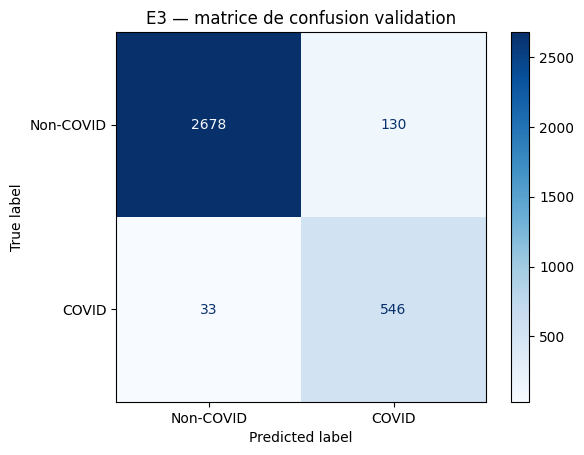

In [23]:
best_model = tf.keras.models.load_model(str(checkpoint_path))
val_generator.reset()
y_proba = best_model.predict(val_generator, verbose=1).ravel()
y_pred = (y_proba >= 0.5).astype(int)
y_true = np.asarray(val_generator.classes)
assert len(y_true) == len(y_pred) == 3387
print(classification_report(y_true, y_pred, target_names=["Non-COVID", "COVID"], digits=4))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Non-COVID", "COVID"]).plot(cmap="Blues")
plt.title("E3 — matrice de confusion validation")
plt.savefig(OUTPUT_DIR / "E3_confusion_validation.png", dpi=180, bbox_inches="tight")
plt.show()
pd.DataFrame({"filepath": val_gen_df["filepath"].to_numpy(),
              "y_true": y_true, "y_proba": y_proba, "y_pred": y_pred}).to_csv(
    OUTPUT_DIR / "E3_predictions_validation.csv", index=False)
pd.DataFrame(classification_report(y_true, y_pred,
    target_names=["Non-COVID", "COVID"], output_dict=True)).T.to_csv(
    OUTPUT_DIR / "E3_classification_report_validation.csv")

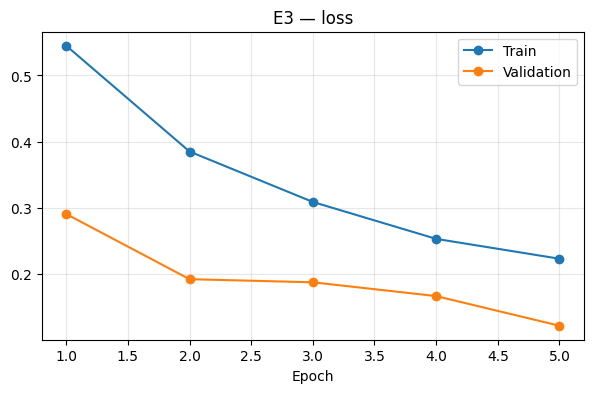

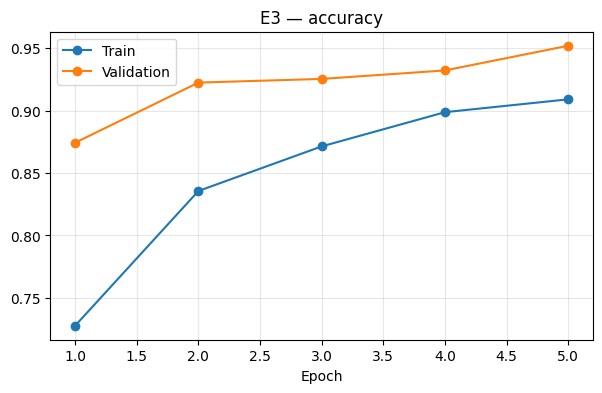

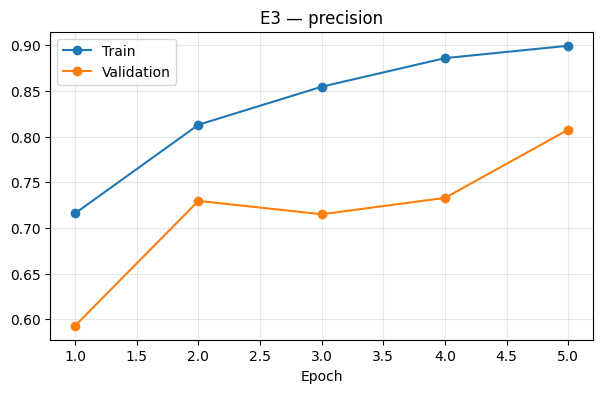

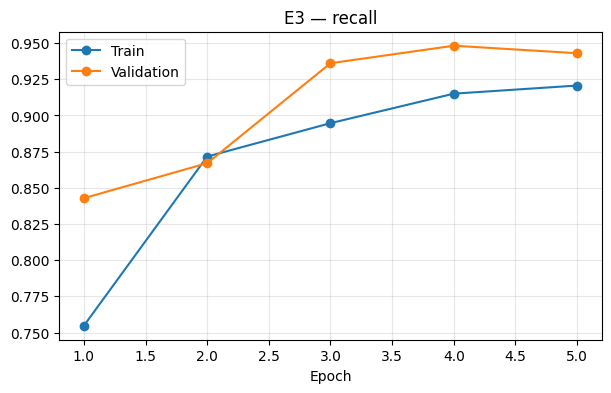

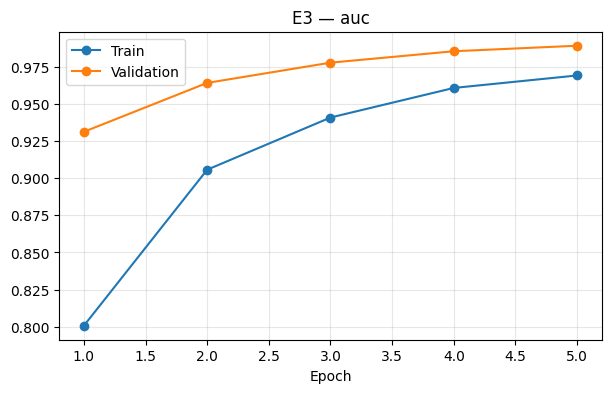

In [24]:
history_df = pd.DataFrame(history.history)
history_df.index = range(1, len(history_df) + 1)
history_df.index.name = "epoch"
for metric in ["loss", "accuracy", "precision", "recall", "auc"]:
    if metric not in history_df or f"val_{metric}" not in history_df:
        continue
    plt.figure(figsize=(7, 4))
    plt.plot(history_df.index, history_df[metric], marker="o", label="Train")
    plt.plot(history_df.index, history_df[f"val_{metric}"], marker="o", label="Validation")
    plt.title(f"E3 — {metric}")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(alpha=.3)
    plt.savefig(OUTPUT_DIR / f"E3_{metric}_curve.png", dpi=180, bbox_inches="tight")
    plt.show()